<a href="https://colab.research.google.com/github/Lathika-M732/24ADI006_DL-_EX-6/blob/main/DL_EX_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IMPLEMENTATION OF LONG SHORT-TERM MEMORY (LSTM) FOR SENTIMENT ANALYSIS

# NAME    :  LATHIKA M
# ROLL NO :  24BAD062

# PART A: DATASET PREPARATION

In [ ]:
# Import the display function again
from IPython.display import display as show_table
import pandas as pd

print("Student: Lathika M_24BAD062")
print("PART A: DATASET PREPARATION")

# Display dataset samples
preview = pd.DataFrame({
    "Encoded Review": [x[:10].tolist() for x in x_train[:5]],
    "Sentiment": [
        "Positive" if y == 1 else "Negative"
        for y in y_train[:5]
    ]
})

show_table(preview)

Student: Lathika M_24BAD062
PART A: DATASET PREPARATION


,Encoded Review,Sentiment
0,"[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65]",Positive
1,"[1, 194, 1153, 194, 8255, 78, 228, 5, 6, 1463]",Negative
2,"[1, 14, 47, 8, 30, 31, 7, 4, 249, 108]",Negative
3,"[1, 4, 2, 2, 33, 2804, 4, 2040, 432, 111]",Positive
4,"[1, 249, 1323, 7, 61, 113, 10, 10, 13, 1637]",Negative


# PART B: IMPLEMENTING THE LSTM MODEL

In [ ]:
# Student details
STUDENT_NAME = "Lathika M"
ROLL_NO = "24BAD062"
STUDENT_ID = f"{STUDENT_NAME}_{ROLL_NO}"

print("Student:", STUDENT_ID)
print("PART B: IMPLEMENTING THE LSTM MODEL")

# Import required libraries
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Create the LSTM model
model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),
    LSTM(
        64,
        dropout=0.2
    ),
    Dropout(0.3),
    Dense(
        1,
        activation="sigmoid"
    )
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()

print("LSTM model compiled successfully.")
print("Student:", STUDENT_ID)

Student: Lathika M_24BAD062
PART B: IMPLEMENTING THE LSTM MODEL


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

LSTM model compiled successfully.
Student: Lathika M_24BAD062


# PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

Train the LSTM model

In [ ]:
# Student details
STUDENT_NAME = "Lathika M"
ROLL_NO = "24BAD062"
STUDENT_ID = f"{STUDENT_NAME}_{ROLL_NO}"

print("Student:", STUDENT_ID)
print("PART C: MODEL TRAINING AND EVALUATION")

# Import required library
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the LSTM model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed successfully.")
print("Student:", STUDENT_ID)

Student: Lathika M_24BAD062
PART C: MODEL TRAINING AND EVALUATION
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 85s 525ms/step - accuracy: 0.5173 - loss: 0.6923 - val_accuracy: 0.5356 - val_loss: 0.6884
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 70s 446ms/step - accuracy: 0.5857 - loss: 0.6680 - val_accuracy: 0.5380 - val_loss: 0.6835
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 78s 499ms/step - accuracy: 0.6370 - loss: 0.6151 - val_accuracy: 0.7808 - val_loss: 0.5234
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 78s 496ms/step - accuracy: 0.7858 - loss: 0.4842 - val_accuracy: 0.5428 - val_loss: 0.9496
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 70s 449ms/step - accuracy: 0.6734 - loss: 0.5694 - val_accuracy: 0.8188 - val_loss: 0.5194
Training completed successfully.
Student: Lathika M_24BAD062


Evaluate model performance

In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from IPython.display import display as show_table
import pandas as pd

print("Student:", STUDENT_ID)
print("MODEL PERFORMANCE EVALUATION")

# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

# Predict sentiments
y_prob = model.predict(
    x_test, batch_size=256, verbose=0
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

# Calculate performance metrics
metrics = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Value": [
        test_loss,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

show_table(metrics)

# Display classification report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

Student: Lathika M_24BAD062
MODEL PERFORMANCE EVALUATION


,Metric,Value
0,Test Loss,0.545525
1,Accuracy,0.807960
2,Precision,0.769592
3,Recall,0.879120
4,F1-Score,0.820718


Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.74      0.79     12500
    Positive       0.77      0.88      0.82     12500

    accuracy                           0.81     25000
   macro avg       0.81      0.81      0.81     25000
weighted avg       0.81      0.81      0.81     25000



Confusion matrix

Student: Lathika M_24BAD062
CONFUSION MATRIX


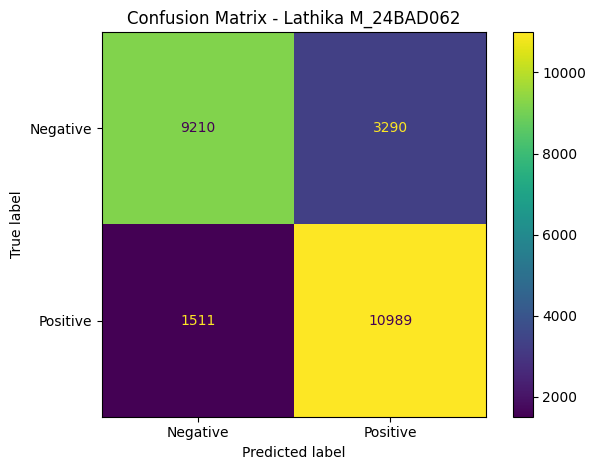

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

print("Student:", STUDENT_ID)
print("CONFUSION MATRIX")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
cm_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

cm_plot.plot(values_format="d")
plt.title(f"Confusion Matrix - {STUDENT_ID}")
plt.tight_layout()
plt.show()

Accuracy and loss graphs

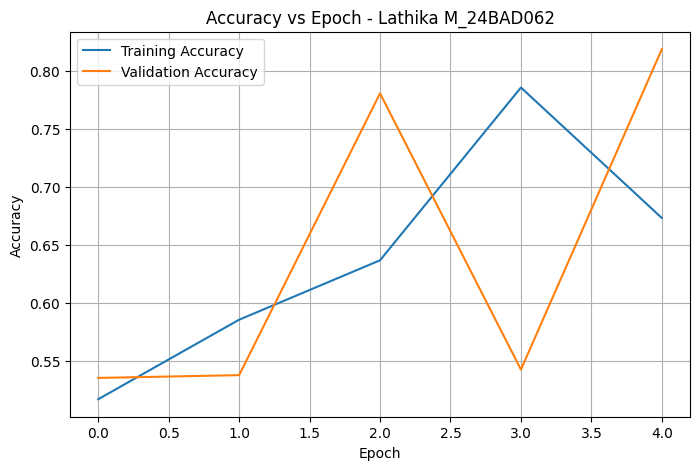

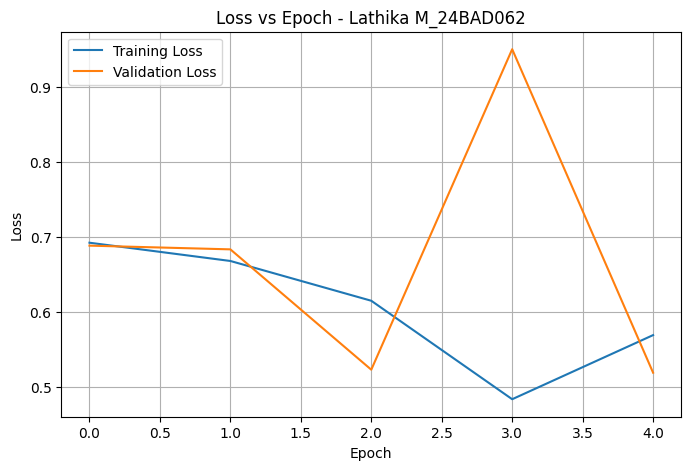

Student: Lathika M_24BAD062


,Metric,Value
0,Training Accuracy,0.673400
1,Validation Accuracy,0.818800
2,Training Loss,0.569428
3,Validation Loss,0.519447


In [ ]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(f"Accuracy vs Epoch - {STUDENT_ID}")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Loss vs Epoch - {STUDENT_ID}")
plt.legend()
plt.grid(True)
plt.show()

# Display final training results
print("Student:", STUDENT_ID)

training_results = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Validation Accuracy",
        "Training Loss",
        "Validation Loss"
    ],
    "Value": [
        history.history["accuracy"][-1],
        history.history["val_accuracy"][-1],
        history.history["loss"][-1],
        history.history["val_loss"][-1]
    ]
})

show_table(training_results)

# PART D: SENTIMENT PREDICTION AND DEEP LEARNING EXPERIMENT MANAGEMENT

Predict sentiment for multiple reviews

In [ ]:
# Student details
STUDENT_NAME = "Lathika M"
ROLL_NO = "24BAD062"
STUDENT_ID = f"{STUDENT_NAME}_{ROLL_NO}"

print("Student:", STUDENT_ID)
print("PART D: SENTIMENT PREDICTION")

import pandas as pd
from IPython.display import display as show_table

# Load the IMDB word dictionary
word_index = imdb.get_word_index()

# Convert text into numerical sequences
def encode_review(text):
    words = text.lower().split()
    sequence = [1]

    for word in words:
        index = word_index.get(word, 2) + 3

        if index >= VOCAB_SIZE:
            index = 2

        sequence.append(index)

    return pad_sequences(
        [sequence],
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

# Predict the sentiment of a review
def predict_sentiment(review):
    sequence = encode_review(review)

    probability = float(
        model.predict(sequence, verbose=0)[0][0]
    )

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    return sentiment, probability

# Test different review samples
reviews = [
    ("This movie was amazing and the acting was excellent.", "Positive"),
    ("The movie was boring and the story was terrible.", "Negative"),
    ("I loved this film and enjoyed every scene.", "Positive"),
    ("I hated this movie and it was a waste of time.", "Negative"),
    ("The story was interesting but the ending was disappointing.", "Mixed")
]

results = []

for review, expected in reviews:
    predicted, probability = predict_sentiment(review)

    results.append({
        "Review": review,
        "Expected Sentiment": expected,
        "Predicted Sentiment": predicted,
        "Positive Probability": round(probability, 4),
        "Comparison": (
            "Correct" if predicted == expected
            else "Incorrect"
        ) if expected in ["Positive", "Negative"]
        else "Mixed review"
    })

show_table(pd.DataFrame(results))

Student: Lathika M_24BAD062
PART D: SENTIMENT PREDICTION


,Review,Expected Sentiment,Predicted Sentiment,Positive Probability,Comparison
0,This movie was amazing and the acting was exce...,Positive,Positive,0.6426,Correct
1,The movie was boring and the story was terrible.,Negative,Positive,0.6426,Incorrect
2,I loved this film and enjoyed every scene.,Positive,Positive,0.6426,Correct
3,I hated this movie and it was a waste of time.,Negative,Positive,0.6425,Incorrect
4,The story was interesting but the ending was d...,Mixed,Positive,0.6426,Mixed review
